# Actividad de evaluación: ¿por qué no sobreviven las colmenas al invierno?

**Estadística para IA, Concentración en IA, Tec de Monterrey**
Jueves 19 de noviembre de 2026. Duración: **2 horas**.


### Reglas

- Individual. Pueden consultar **solo** las slides del curso (GLMs bayesianos y modelos jerárquicos) y la chuleta de PyMC que viene en este notebook. Nada de internet, notebooks anteriores ni asistentes de IA.
- Entregan **este notebook ejecutado**, con sus respuestas en las celdas que dicen **Respuesta**.
- Escriban cada respuesta en sus palabras, en pocas líneas. Un número sin interpretación vale poco; una interpretación correcta acompañada de un error menor de código vale mucho.
- Siempre que reporten una cantidad estimada, den **mediana e intervalo del 95%**.

### Qué se califica y tiempos sugeridos

| Parte | Tema | Puntos | Tiempo sugerido |
|---|---|---|---|
| 0 | Leer la situación y el análisis exploratorio | 15 | 20 min |
| A | ¿De qué depende la infestación de ácaros? | 25 | 30 min |
| B | ¿Qué apiarios lo hacen mejor? | 25 | 30 min |
| C | ¿Sirve el acaricida? | 35 | 40 min |
| | Extras (opcionales, marcados como **Extra**) | hasta +10 | |

El análisis exploratorio ya está hecho: **lean las gráficas con calma**, porque casi todas las decisiones de modelado que les voy a pedir están sugeridas ahí. Cada modelo tarda entre 20 segundos y un par de minutos en muestrear; mientras corre uno, avancen con la interpretación del anterior.

## La situación

Una cooperativa de apicultores de Nuevo León y Coahuila tiene **40 apiarios** (un apiario es un terreno con varias colmenas, a cargo de un apicultor). Los últimos inviernos han perdido muchas colmenas, y la sospecha principal es el **ácaro varroa**, un parásito que se alimenta de las abejas y les transmite virus.

El año pasado la cooperativa siguió a **todas sus colmenas** con el mismo protocolo:

| Momento | Qué pasa | Variables |
|---|---|---|
| Octubre | Inspección de cada colmena: se cuentan los bastidores (marcos) cubiertos de abejas, y se toma una muestra de abejas en alcohol para contar cuántos ácaros traen. La muestra se mide con un vaso, así que el número de abejas varía de colmena a colmena. | `bastidores`, `abejas_muestra`, `acaros`, `linea_higienica`, `edad_reina` |
| Octubre, después del conteo | Cada apicultor **decide** si aplica un acaricida a la colmena. | `tratada` |
| Diciembre | Se pesa la colmena para estimar las reservas de miel con las que entra al invierno. | `kg_miel_dic` |
| Marzo | ¿La colmena sobrevivió al invierno? | `sobrevivio` |

Además, de cada apiario se conoce su altitud y cuántas colmenas de **otros** apicultores hay a menos de 3 km (los ácaros se pasan de una colmena a otra cuando las abejas se roban miel o se equivocan de casa).

### Diccionario de datos (`colmenas_invierno.csv`, un renglón por colmena)

| variable | descripción |
|---|---|
| `colmena` | identificador de la colmena |
| `apiario` | apiario al que pertenece (`A01` a `A40`) |
| `altitud_m` | altitud del apiario, en metros |
| `colmenas_vecinas` | colmenas de otros apicultores a menos de 3 km del apiario, **en cientos** (2.5 = 250 colmenas) |
| `linea_higienica` | 1 si la reina viene de una línea comercial seleccionada por comportamiento higiénico (las obreras detectan y sacan cría parasitada); 0 si es reina local |
| `edad_reina` | edad de la reina en años (1, 2 o 3) |
| `bastidores` | bastidores cubiertos de abejas en octubre (fuerza de la colonia; de 3 a 10) |
| `abejas_muestra` | abejas en la muestra de alcohol |
| `acaros` | ácaros contados en esa muestra |
| `tratada` | 1 si el apicultor aplicó acaricida en octubre |
| `kg_miel_dic` | reservas de miel estimadas en diciembre, en kg |
| `sobrevivio` | 1 si la colmena seguía viva en marzo |

La cooperativa usa como regla práctica que una infestación de **más de 3 ácaros por cada 100 abejas** en octubre es preocupante.

Los datos son ficticios, pero el problema y el protocolo son realistas.

## Codigos de PyMC (solo sintaxis)

Estas son piezas sueltas, no un modelo. Ustedes deciden cuáles usar y cómo combinarlas.

```python
with pm.Model(coords={"apiario": nombres_api, "pred": ["x1", "x2"]}) as modelo:
    # priors
    a = pm.Normal("a", mu=0, sigma=1.5)
    b = pm.Normal("b", mu=0, sigma=1, dims="pred")          # un vector de coeficientes
    s = pm.HalfNormal("s", sigma=1)                          # parámetro positivo
    r = pm.Exponential("r", lam=0.5)                         # parámetro positivo, media 1/lam
    z = pm.Normal("z", 0, 1, dims="apiario")                 # un valor por apiario

    # expresiones
    eta = a + pm.math.dot(X, b)                              # X: arreglo de numpy de forma (n, 2)
    v = z[api_idx]                                           # un valor por renglón, según su apiario
    pm.Deterministic("nombre", expresion, dims="apiario")    # guardar una cantidad en el posterior

    # verosimilitudes: observed= convierte la línea en verosimilitud
    pm.Poisson("y", mu=m, observed=y)
    pm.NegativeBinomial("y", mu=m, alpha=r, observed=y)      # Var(y) = m + m**2 / r
    pm.Bernoulli("y", logit_p=eta, observed=y)               # equivale a p = invlogit(eta)
    pm.Binomial("y", n=n, p=p, observed=y)

    # muestrear (y simular datos replicados para chequeos predictivos)
    idata = pm.sample(1000, tune=1000, chains=4, target_accept=0.9, random_seed=SEMILLA)
    pm.sample_posterior_predictive(idata, extend_inplace=True, random_seed=SEMILLA)

az.summary(idata, var_names=["a", "b"], round_to=3)          # medias, hdi, r_hat, ess
# funciones dentro del modelo: pm.math.exp, pm.math.log, pm.math.invlogit, pm.math.dot
```

Fuera del modelo, con muestras (todas las funciones de abajo ya están cargadas):

```python
muestras(idata, "b")                                  # arreglo (S, ...) con S = cadenas x draws
muestras(idata, "y", grupo="posterior_predictive")    # datos replicados, forma (S, n)
resumen(v, "nombre")                                  # mediana e intervalo del 95% de un vector
expit(x)                                              # invlogit, en numpy
rng.normal(0, 1, size=S); rng.binomial(n, p)
rng.negative_binomial(r, r / (r + m))                 # misma binomial negativa que la de PyMC (media m)
np.column_stack([x1, x2])                             # pegar columnas para armar X
```

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pymc as pm
import arviz as az
from scipy.special import expit, logit

print("PyMC", pm.__version__, "| ArviZ", az.__version__)

SEMILLA = 2026
rng = np.random.default_rng(SEMILLA)
plt.rcParams.update({"figure.figsize": (7, 4), "axes.spines.top": False,
                     "axes.spines.right": False, "font.size": 10})


def muestras(idata, var, grupo="posterior"):
    # Muestras de `var` como arreglo de numpy, juntando cadenas: forma (S, ...)
    v = np.asarray(getattr(idata, grupo)[var])
    return v.reshape(-1, *v.shape[2:])


def resumen(v, nombre="", decimales=3):
    # Mediana e intervalo central del 95% de un vector de muestras
    q = np.percentile(v, [2.5, 50, 97.5])
    d = decimales
    print(f"{nombre:>45s}: {q[1]:9.{d}f}   [{q[0]:9.{d}f}, {q[2]:9.{d}f}]")


def divergencias(idata):
    # Número de transiciones divergentes (lo ideal: 0)
    return int(np.asarray(idata.sample_stats["diverging"]).sum())


def chequeo(idata, var, y_obs, estadistico, nombre, mascara=None):
    # Chequeo predictivo posterior de un estadístico T: T(datos) contra T(datos replicados)
    y_rep = muestras(idata, var, grupo="posterior_predictive")
    if mascara is not None:
        y_rep, y_obs = y_rep[:, mascara], y_obs[mascara]
    t_rep = np.array([estadistico(fila) for fila in y_rep])
    t_obs = estadistico(y_obs)
    q = np.percentile(t_rep, [2.5, 50, 97.5])
    print(f"{nombre:>34s}   datos: {t_obs:9.3f}   modelo: {q[1]:9.3f} [{q[0]:9.3f}, {q[2]:9.3f}]"
          f"   P(T_rep >= T_obs) = {np.mean(t_rep >= t_obs):.3f}")


def chequeo_apiarios(idata, var="acaros"):
    # Chequeo a nivel apiario: T = desviación estándar, entre los 40 apiarios,
    # del log de la tasa de ácaros por abeja de cada apiario (todas sus colmenas juntas)
    def T(y):
        tasa = (np.bincount(api_idx, y, J) + 0.5) / np.bincount(api_idx, abejas, J)
        return np.std(np.log(tasa))
    chequeo(idata, var, acaros, T, "d.e. entre apiarios de log(tasa)")


def prob_top_k(M, k=5, mayores=True):
    # M: arreglo (S, J), una columna por apiario. Regresa, para cada apiario, la probabilidad
    # posterior de estar entre los k mayores (o los k menores, con mayores=False).
    M = np.asarray(M) if mayores else -np.asarray(M)
    orden = np.argsort(-M, axis=1)[:, :k]
    conteo = np.zeros(M.shape[1])
    for c in range(k):
        conteo += np.bincount(orden[:, c], minlength=M.shape[1])
    return pd.Series(conteo / M.shape[0], index=nombres_api)


def grafica_encogimiento(p_crudo, n, p_modelo, titulo=""):
    # Proporción cruda de cada apiario contra la estimación del modelo
    fig, ax = plt.subplots(figsize=(6.5, 5))
    ax.scatter(p_crudo, p_modelo, s=n * 3, alpha=0.6, edgecolor="k")
    for x, y_, nombre in zip(p_crudo, p_modelo, nombres_api):
        if abs(x - y_) > 0.06 or x == 1:
            ax.annotate(nombre, (x, y_), fontsize=7, xytext=(4, -3), textcoords="offset points")
    lim = [min(p_crudo.min(), p_modelo.min()) - 0.03, 1.02]
    ax.plot(lim, lim, ls=":", color="gray")
    ax.axhline(np.mean(sobrev), color="C3", lw=1, label="proporción global")
    ax.set_xlabel("proporción cruda del apiario")
    ax.set_ylabel("estimación del modelo (mediana)")
    ax.set_title(titulo)
    ax.legend(loc="upper left")
    plt.show()

PyMC 5.28.5 | ArviZ 0.22.0



# Parte 0. Análisis exploratorio (ya hecho)

Corran las celdas en orden y lean cada gráfica antes de contestar. Las preguntas de esta parte (**E1** a **E5**) se contestan **sin modelar**.

## Niveles y tamaños

In [3]:
datos = pd.read_csv("colmenas_invierno.csv")
print(datos.shape)
datos.head()

(1205, 12)


,colmena,apiario,altitud_m,colmenas_vecinas,linea_higienica,edad_reina,bastidores,abejas_muestra,acaros,tratada,kg_miel_dic,sobrevivio
0,1,A01,560,4.3,0,2,8,284,47,1,12.4,0
1,2,A01,560,4.3,0,2,8,272,11,1,15.1,1
2,3,A01,560,4.3,1,1,8,240,8,1,13.5,1
3,4,A01,560,4.3,0,3,6,210,24,1,10.0,1
4,5,A01,560,4.3,0,1,4,187,24,1,4.8,0


In [4]:
# ¿Cuántos valores distintos toma cada variable DENTRO de un mismo apiario? (el máximo sobre los 40)
distintos = datos.drop(columns="colmena").groupby("apiario").nunique().max()
distintos.to_frame("máx. valores distintos dentro de un apiario")

,máx. valores distintos dentro de un apiario
altitud_m,1
colmenas_vecinas,1
linea_higienica,2
edad_reina,3
bastidores,8
abejas_muestra,80
acaros,32
tratada,2
kg_miel_dic,69
sobrevivio,2


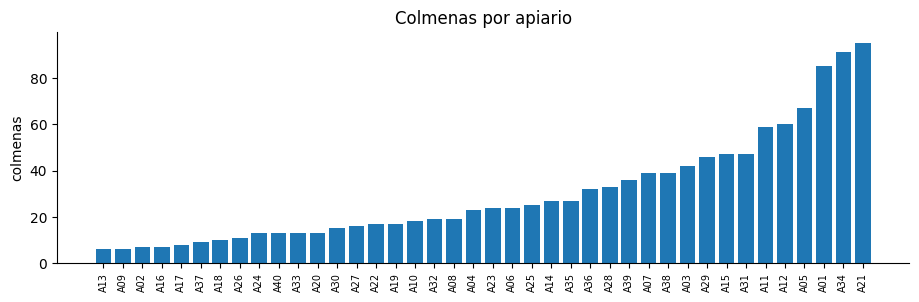

40 apiarios, con entre 6 y 95 colmenas (mediana 24); 1205 colmenas en total


In [5]:
por_apiario = datos.groupby("apiario").size().sort_values()
fig, ax = plt.subplots(figsize=(11, 3))
ax.bar(por_apiario.index, por_apiario.values, color="C0")
ax.set_ylabel("colmenas")
ax.tick_params(axis="x", rotation=90, labelsize=7)
ax.set_title("Colmenas por apiario")
plt.show()
print(f"{len(por_apiario)} apiarios, con entre {por_apiario.min()} y {por_apiario.max()} colmenas "
      f"(mediana {por_apiario.median():.0f}); {len(datos)} colmenas en total")

> **E1** (3 pts). Con la tabla y la gráfica: ¿qué variables viven en el nivel **apiario** y cuáles en el nivel **colmena**? ¿Qué tan desbalanceados están los apiarios, y por qué eso va a importar cuando los comparemos?

**Respuesta E1.**

* Clasificación de variables a nivel apiario o colmena:

| variable | clasificación |
|---|---|
| `colmena` | identificador |
| `apiario` | identificador |
| `altitud_m` | apiario |
| `colmenas_vecinas` | apiario |
| `linea_higienica` | colmena |
| `edad_reina` | colmena |
| `bastidores` | colmena |
| `abejas_muestra` | colmena |
| `acaros` | colmena|
| `tratada` | colmena |
| `kg_miel_dic` | colmena |
| `sobrevivio` | colmena |

<br>

* Desbalance de los apiarios:

Hay un desbalance claro entre los apiarios. El conjunto tiene 40 apiarios con una mediana de 24 colmenas, pero los tamaños van desde 6 hasta 95 colmenas. La concentración de colmenas no está equilibrada entre apiarios, lo cual se aprecia claramente en la forma de la gráfica. Esto puede resultar problemático, ya que los apiarios con pocas colmenas tendrán estimaciones más ruidosas e inestables que los grandes.


## Los conteos de ácaros

In [6]:
datos["infest"] = 100 * datos["acaros"] / datos["abejas_muestra"]                       # ácaros por cada 100 abejas
datos["log_infest"] = np.log(100 * (datos["acaros"] + 0.5) / datos["abejas_muestra"])  # +0.5 porque hay ceros

a_ = datos["acaros"]
print(f"ácaros por muestra:  media {a_.mean():.2f}   varianza {a_.var():.1f}   "
      f"varianza/media {a_.var() / a_.mean():.1f}   proporción de ceros {np.mean(a_ == 0):.3f}   máximo {a_.max()}")
print(f"abejas por muestra:  de {datos.abejas_muestra.min()} a {datos.abejas_muestra.max()}")
print(f"infestación (ácaros por 100 abejas):  mediana {datos.infest.median():.2f}   "
      f"colmenas arriba de 3: {np.mean(datos.infest > 3):.2f}")

ácaros por muestra:  media 7.97   varianza 91.2   varianza/media 11.4   proporción de ceros 0.077   máximo 117
abejas por muestra:  de 120 a 420
infestación (ácaros por 100 abejas):  mediana 2.00   colmenas arriba de 3: 0.34


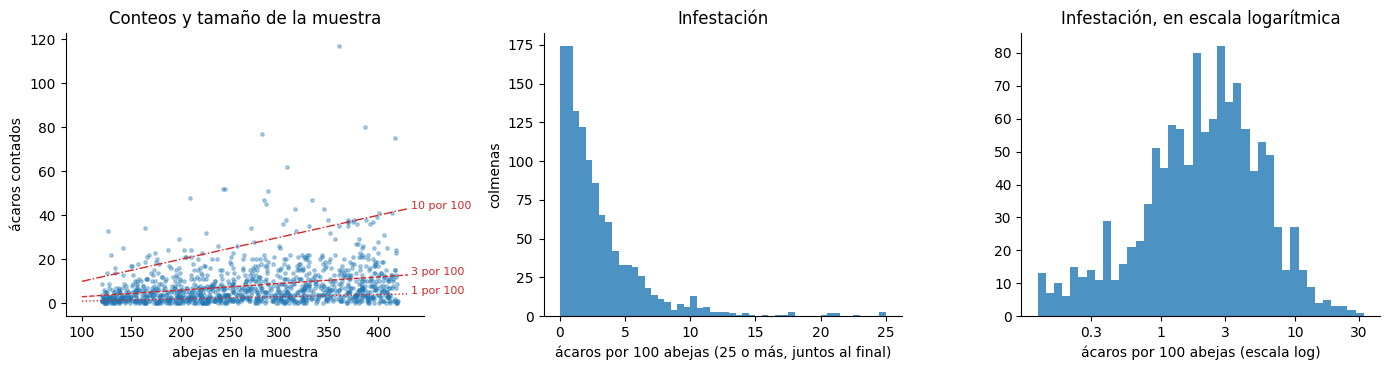

In [7]:
fig, axs = plt.subplots(1, 3, figsize=(14, 3.8))

ax = axs[0]
ax.scatter(datos.abejas_muestra, datos.acaros, s=6, alpha=0.35)
xx = np.array([100, 430])
for r, estilo in [(1, ":"), (3, "--"), (10, "-.")]:
    ax.plot(xx, r / 100 * xx, estilo, color="C3", lw=1)
    ax.annotate(f"{r} por 100", (430, r / 100 * 430), fontsize=8, color="C3", xytext=(2, 0),
                textcoords="offset points")
ax.set_xlabel("abejas en la muestra")
ax.set_ylabel("ácaros contados")
ax.set_title("Conteos y tamaño de la muestra")

ax = axs[1]
ax.hist(np.minimum(datos.infest, 25), bins=50, color="C0", alpha=0.8)
ax.set_xlabel("ácaros por 100 abejas (25 o más, juntos al final)")
ax.set_ylabel("colmenas")
ax.set_title("Infestación")

ax = axs[2]
ax.hist(datos.log_infest, bins=40, color="C0", alpha=0.8)
ticks = [0.3, 1, 3, 10, 30]
ax.set_xticks(np.log(ticks), [str(t) for t in ticks])
ax.set_xlabel("ácaros por 100 abejas (escala log)")
ax.set_title("Infestación, en escala logarítmica")
plt.tight_layout()
plt.show()

> **E2** (3 pts). (a) ¿Qué papel debería jugar `abejas_muestra` en un modelo para `acaros`? Sean precisos: ¿entra como un predictor más, con su propio coeficiente, o de otra forma? ¿Por qué? (b) ¿Qué familia de distribución considerarían para `acaros`, y qué número de los de arriba apoya su elección?

**Respuesta E2.**

* Papel de `abejas_muestra` en modelo para `acaros`:

Al crear un modelo para `acaros`, clasificaría la variable de `abejas_muestra` como offset, ya que la media del conteo es `abejas_muestra × tasa`, o sea, el número de ácaros crece con el número de abejas revisadas. Con este enfoque se puede estimar realmente la tasa de infestación, no solamente un conteo que no tome en cuenta el tamaño de la muestra.

* Familia de distribución para `acaros`:

***> ! Pendiente !!!!!*** ⚠️️️️️️️️️️ ⚠️️️️️️️️️️ ⚠️️️️️️️️️️ ⚠️️️️️️️️️️ ⚠️️️️️️️️️️ ⚠️️️️️️️️️️ ⚠️️️️️️️️️️ ⚠️️️️️️️️️️ ⚠️️️️️️️️️️ ⚠️️️️️️️️️️

## Infestación por apiario

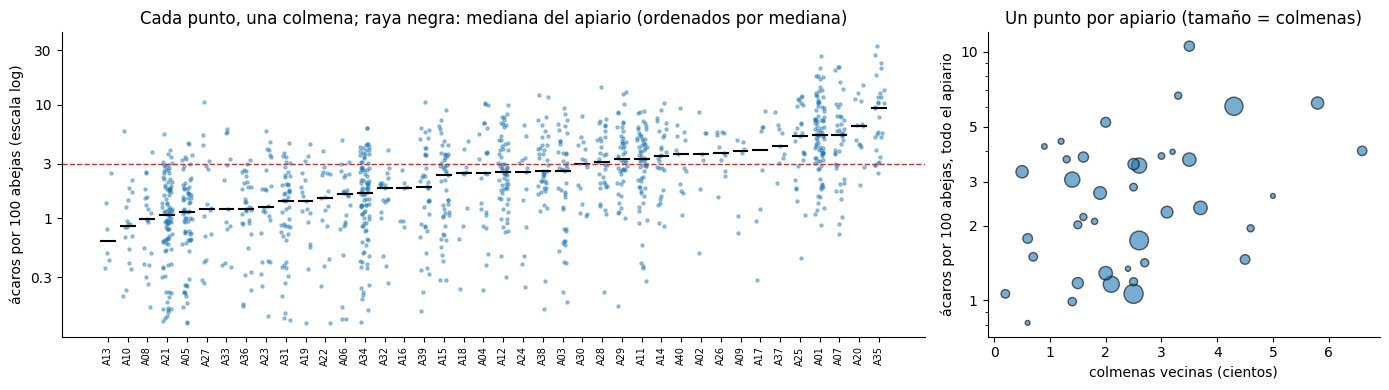

                colmenas      mediana      
linea_higienica        0    1       0     1
edad_reina                                 
1                    376  166    2.11  1.15
2                    269  127    2.58  1.36
3                    182   85    2.89  1.67


In [8]:
orden = datos.groupby("apiario").log_infest.median().sort_values().index
fig, axs = plt.subplots(1, 2, figsize=(14, 4), gridspec_kw={"width_ratios": [2.2, 1]})

ax = axs[0]
for k, ap in enumerate(orden):
    v_ = datos.loc[datos.apiario == ap, "log_infest"].values
    ax.scatter(k + rng.uniform(-0.25, 0.25, len(v_)), v_, s=5, alpha=0.4, color="C0")
    ax.plot([k - 0.35, k + 0.35], [np.median(v_)] * 2, color="k", lw=1.5)
ax.set_xticks(range(len(orden)), orden, rotation=90, fontsize=7)
ax.set_yticks(np.log(ticks), [str(t) for t in ticks])
ax.axhline(np.log(3), color="C3", ls="--", lw=1)
ax.set_ylabel("ácaros por 100 abejas (escala log)")
ax.set_title("Cada punto, una colmena; raya negra: mediana del apiario (ordenados por mediana)")

ax = axs[1]
api_ac = datos.groupby("apiario").agg(n=("acaros", "size"), ac=("acaros", "sum"), ab=("abejas_muestra", "sum"),
                                      vecinas=("colmenas_vecinas", "first"))
ax.scatter(api_ac.vecinas, 100 * api_ac.ac / api_ac.ab, s=api_ac.n * 2, alpha=0.6, edgecolor="k")
ax.set_yscale("log")
ax.set_yticks([1, 2, 3, 5, 10], ["1", "2", "3", "5", "10"])
ax.set_xlabel("colmenas vecinas (cientos)")
ax.set_ylabel("ácaros por 100 abejas, todo el apiario")
ax.set_title("Un punto por apiario (tamaño = colmenas)")
plt.tight_layout()
plt.show()

print(datos.groupby(["linea_higienica", "edad_reina"]).infest.agg(colmenas="size", mediana="median").round(2).unstack(0))

> **E3** (3 pts). (a) ¿Las colmenas de un mismo apiario se parecen entre sí en su infestación? (b) Si un modelo trata las 1,205 colmenas como independientes, ¿qué esperarían que le pase al intervalo del efecto de `colmenas_vecinas`? Piensen en cuántas observaciones distintas hay de esa variable. (c) Con la tabla: ¿parece ayudar la línea higiénica? ¿Y la edad de la reina?

**Respuesta E3.**

* ¿Las colmenas de un mismo apiario se parecen entre sí en su infestación?

Sí, las colmenas de un mismo apiario si se parecen entre sí en su infestación. Se puede observar una diferencia evidente entre apiarios, donde el nivel de infestación (ácaros por 100 abejas) varía mucho de un apiario a otro. En cambio, dentro de un mismo apiario las colmenas tienden a agruparse alrededor de un nivel similar, amplio, pero al final en forma de grupos/rangos similares en un mismo apiario. Esa similitud dentro del apiario es la que justifica un efecto aleatorio por apiario.


* Si un modelo trata las 1,205 colmenas como independientes, ¿qué esperarían que le pase al intervalo del efecto de `colmenas_vecinas`?

La variable `colmenas_vecinas` presenta un solo valor distinto dentro de cada apiario, o sea, es constante por apiario. Si se tratan las colmenas como independientes, se describiría cada observamiento como único y a nivel apiario se contaría muchas veces la misma observación, lo que podría ocasionar que se infle el tamaño de muestra de esta variable y disminuir su precisión. Se debe buscar un enfoque que no elimine la variable, pero que no considere cada valor como algo distinto, sino que agrupe con base en ella.


* Con la tabla: ¿parece ayudar la línea higiénica? ¿Y la edad de la reina?

La tabla de no aporta suficiente información para determinar si la línea higiénica o la edad de la reina ayudan, pues solo indica que ambas variables varían dentro de los apiarios (colmenas con y sin línea higiénica, y reinas de 1 a 3 años). Para saber si ayudan hay que comparar con variables más específicas como la infestación o la supervivencia por grupo.



## Supervivencia por apiario

Supervivencia global: 0.738


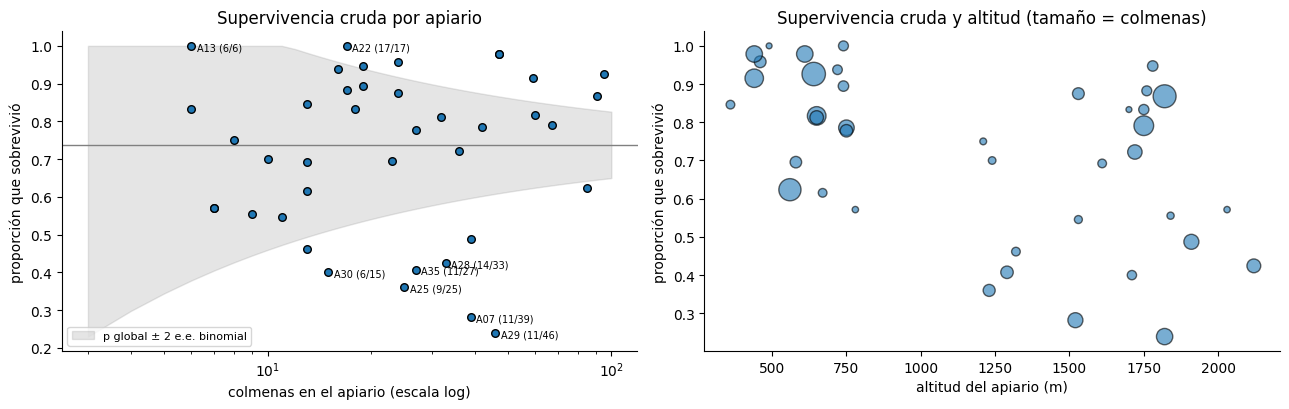

In [9]:
api = datos.groupby("apiario").agg(n=("sobrevivio", "size"), sobreviven=("sobrevivio", "sum"),
                                   altitud_m=("altitud_m", "first"))
api["prop"] = api.sobreviven / api.n
p0 = datos.sobrevivio.mean()
print(f"Supervivencia global: {p0:.3f}")

fig, axs = plt.subplots(1, 2, figsize=(13, 4.2))
ax = axs[0]
nn = np.arange(3, 101)
banda = 2 * np.sqrt(p0 * (1 - p0) / nn)
ax.fill_between(nn, p0 - banda, np.minimum(p0 + banda, 1), color="gray", alpha=0.2,
                label="p global ± 2 e.e. binomial")
ax.axhline(p0, color="gray", lw=1)
ax.scatter(api.n, api.prop, s=30, color="C0", edgecolor="k", zorder=3)
for nombre, f in api.iterrows():
    if f.prop == 1 or f.prop < 0.45:
        ax.annotate(f"{nombre} ({int(f.sobreviven)}/{int(f.n)})", (f.n, f.prop), fontsize=7,
                    xytext=(4, -3), textcoords="offset points")
ax.set_xscale("log")
ax.set_xlabel("colmenas en el apiario (escala log)")
ax.set_ylabel("proporción que sobrevivió")
ax.set_title("Supervivencia cruda por apiario")
ax.legend(loc="lower left", fontsize=8)

ax = axs[1]
ax.scatter(api.altitud_m, api.prop, s=api.n * 3, alpha=0.6, edgecolor="k")
ax.set_xlabel("altitud del apiario (m)")
ax.set_ylabel("proporción que sobrevivió")
ax.set_title("Supervivencia cruda y altitud (tamaño = colmenas)")
plt.tight_layout()
plt.show()

> **E4** (3 pts). (a) En la gráfica de la izquierda, ¿qué tienen en común los apiarios que aparecen en los extremos? ¿Creen que A13 y A22 son los mejores apiarios de la cooperativa? (b) ¿Qué sugiere la gráfica de la derecha?

**Respuesta E4.**

* En la gráfica de la izquierda, ¿qué tienen en común los apiarios que aparecen en los extremos? ¿Creen que A13 y A22 son los mejores apiarios de la cooperativa?

Los apiarios de los extremos tienen tasas de supervivencia mucho más altas o mucho más bajas que el resto, y en la escala log aparecen con una proporción de colmenas más grande, lo que podría indicar que esos resultados extremos se deben a tamaños de muestra más grandes. A13 y A22 presentan la tasa de supervivencia más alta (sobreviven todas sus colmenas), pero no significa necesariamente que sean los mejores apiarios. Sus muestras son muy chicas (A13 tiene 6 colmenas y A22 tiene 17), mientras que otros apiarios, por ejemplo, sobreviven 14 colmenas de 33. Estee dato puede ser engañoso si no se interpreta con cuidado.

* ¿Qué sugiere la gráfica de la derecha?

En la gráfica de la derecha se observa un agrupamiento por proporción de supervivencia y altitud del apiario, donde el grupo con mayor supervivencia se ubica por debajo de los 750 m de altitud, mientras que el resto se dispersa a partir de los 1250 m aproximadamente. Esto sugiere que la altitud podría estar asociada con la supervivencia, pero no se puede concluir que la supervivencia está dada por la altura. Además, se puede apreciar que no hay información de apiarios entre 750 y 1250 m, pero no se puede concluir que no puedan existir apiarios entre estas altitudes, ya que la gráfica solo muestra los apiarios observados y la ausencia de puntos puede deberse a factores externos, no a que sea imposible.

## Supervivencia, infestación, fuerza y tratamiento

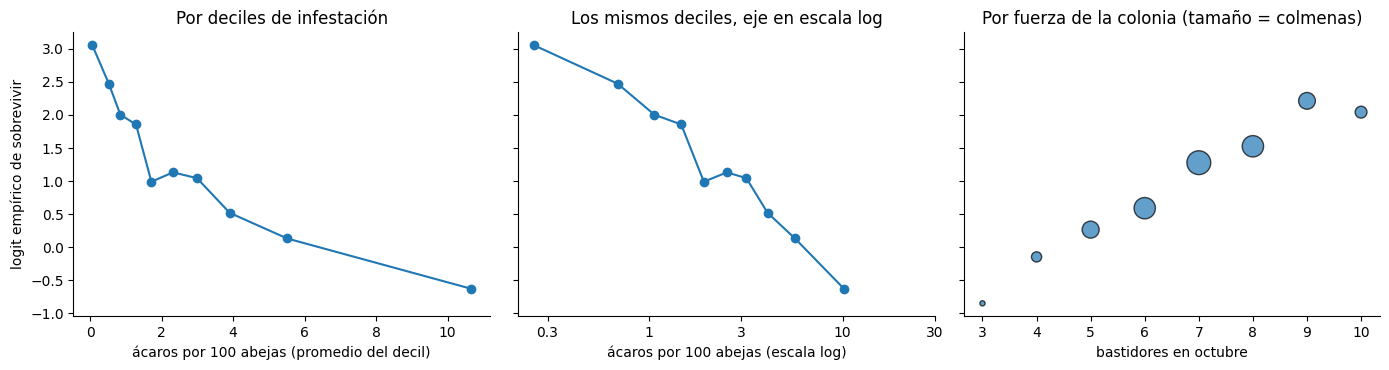

In [10]:
def logit_empirico(s, n):
    return np.log((s + 0.5) / (n - s + 0.5))

grupos = pd.qcut(datos.log_infest, 10)
tab = datos.groupby(grupos, observed=True).agg(n=("sobrevivio", "size"), s=("sobrevivio", "sum"),
                                                infest=("infest", "mean"), log_infest=("log_infest", "mean"))
tab["logit_emp"] = logit_empirico(tab.s, tab.n)
tab_b = datos.groupby("bastidores").agg(n=("sobrevivio", "size"), s=("sobrevivio", "sum"))
tab_b["logit_emp"] = logit_empirico(tab_b.s, tab_b.n)

fig, axs = plt.subplots(1, 3, figsize=(14, 3.8), sharey=True)
axs[0].plot(tab.infest, tab.logit_emp, "o-")
axs[0].set_xlabel("ácaros por 100 abejas (promedio del decil)")
axs[0].set_ylabel("logit empírico de sobrevivir")
axs[0].set_title("Por deciles de infestación")
axs[1].plot(tab.log_infest, tab.logit_emp, "o-")
axs[1].set_xticks(np.log(ticks), [str(t) for t in ticks])
axs[1].set_xlabel("ácaros por 100 abejas (escala log)")
axs[1].set_title("Los mismos deciles, eje en escala log")
axs[2].scatter(tab_b.index, tab_b.logit_emp, s=tab_b.n, alpha=0.7, edgecolor="k")
axs[2].set_xlabel("bastidores en octubre")
axs[2].set_title("Por fuerza de la colonia (tamaño = colmenas)")
plt.tight_layout()
plt.show()

         colmenas  prop_sobrevive  infest_mediana  miel_media
tratada                                                      
0             770           0.803           1.196      10.372
1             435           0.623           4.487      10.966


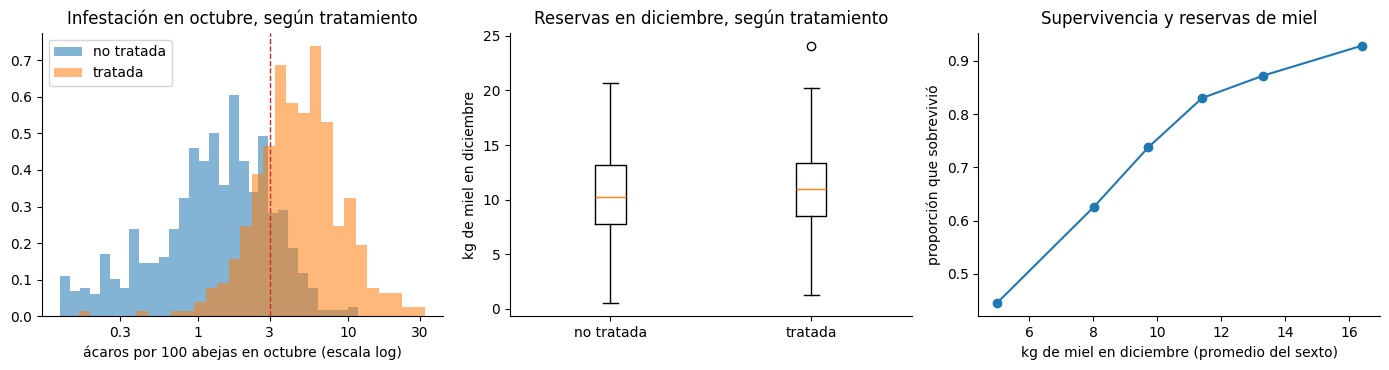

In [11]:
print(datos.groupby("tratada").agg(colmenas=("sobrevivio", "size"),
                                   prop_sobrevive=("sobrevivio", "mean"),
                                   infest_mediana=("infest", "median"),
                                   miel_media=("kg_miel_dic", "mean")).round(3))

fig, axs = plt.subplots(1, 3, figsize=(14, 3.8))
ax = axs[0]
for t, color, etiqueta in [(0, "C0", "no tratada"), (1, "C1", "tratada")]:
    ax.hist(datos.log_infest[datos.tratada == t], bins=30, alpha=0.55, color=color, label=etiqueta, density=True)
ax.set_xticks(np.log(ticks), [str(t) for t in ticks])
ax.axvline(np.log(3), color="C3", ls="--", lw=1)
ax.set_xlabel("ácaros por 100 abejas en octubre (escala log)")
ax.set_title("Infestación en octubre, según tratamiento")
ax.legend()

ax = axs[1]
ax.boxplot([datos.kg_miel_dic[datos.tratada == 0], datos.kg_miel_dic[datos.tratada == 1]])
ax.set_xticks([1, 2], ["no tratada", "tratada"])
ax.set_ylabel("kg de miel en diciembre")
ax.set_title("Reservas en diciembre, según tratamiento")

ax = axs[2]
q_miel = pd.qcut(datos.kg_miel_dic, 6)
tm = datos.groupby(q_miel, observed=True).agg(miel=("kg_miel_dic", "mean"), p=("sobrevivio", "mean"))
ax.plot(tm.miel, tm.p, "o-")
ax.set_xlabel("kg de miel en diciembre (promedio del sexto)")
ax.set_ylabel("proporción que sobrevivió")
ax.set_title("Supervivencia y reservas de miel")
plt.tight_layout()
plt.show()

> **E5** (3 pts). (a) ¿En qué escala conviene meter la infestación como predictor en una regresión logística de la supervivencia? ¿Y los bastidores? (b) Con la tabla y las tres gráficas del tratamiento: ¿qué concluiría alguien con prisa sobre el acaricida? Usando la **línea de tiempo** de la situación, propongan una explicación alternativa. ¿Qué papel juega `kg_miel_dic` en esa historia? (No hace falta modelar todavía.)

**Respuesta E5.**
* ¿En qué escala conviene meter la infestación como predictor en una regresión logística de la supervivencia? ¿Y los bastidores?

La infestación conviene meterla en escala logarítmica, puesto que los ácaros por 100 abejas tienen una distribución muy asimétrica. Los bastidores, en cambio, pueden entrar en su escala original (lineal) porque van de 3 a 10 sin cola larga.

* Con la tabla y las tres gráficas del tratamiento: ¿qué concluiría alguien con prisa sobre el acaricida? Usando la **línea de tiempo** de la situación, propongan una explicación alternativa. ¿Qué papel juega `kg_miel_dic` en esa historia? (No hace falta modelar todavía.)

Si alguien revisara los datos rápidamente, podría asumir que no hay diferencia entre las colmenas tratadas y las no tratadas, pues sus valores son similares y parecería que el tratamiento es irrelevante. Esto tendría una implicación muy grande, pues podría llevar a cancelar esta medida y afectar negativamente a las abejas.

Por otro lado, lo que ocurre realmente es un solapamiento de información en el tiempo y una serie de implicaciones ocultas. Primero, la comparación no es entre las mismas colmenas antes y después, el acaricida se aplica después del conteo de octubre, así que las colmenas tratadas y no tratadas no son comparables directamente. Si se estudian colmenas distintas, se pueden ignorar otros factores que también afectan la supervivencia y por ende, llevar a una interpretación incorrecta. Además, puede ser que existan factores ocultos que no se están tomando en cuenta, por ejemplo, es probable que los apicultores trataran las colmenas más infestadas o más débiles, por lo que las tratadas parten de una situación peor. Así, que las proporciones de supervivencia sean parecidas podría significar que el tratamiento sí ayudó,pues sin él, esas colmenas habrían estado peor. En esa contexto, `kg_miel_dic` es el reflejo del resultado del acaricida: el tratamiento reduce la infestación, lo que a su vez permite conservar más reservas de miel en diciembre, y esas reservas son las que ayudan a sobrevivir al invierno (una cadena de sucesos que no necesariamente se ve a simple vista).

## Arreglos listos para modelar

Para que no pierdan tiempo en esto, aquí están los arreglos que van a necesitar. Varios predictores ya vienen **centrados**, para que el intercepto se refiera a una colmena típica y el muestreador trabaje mejor. Lean los comentarios: ahí dice en qué unidades está cada uno.

In [12]:
apiarios = datos.groupby("apiario").agg(n_colmenas=("colmena", "size"), altitud_m=("altitud_m", "first"),
                                        colmenas_vecinas=("colmenas_vecinas", "first")).reset_index()
nombres_api = apiarios["apiario"].values
J = len(apiarios)
api_idx = pd.Categorical(datos["apiario"], categories=nombres_api).codes.astype(int)   # j[i]: de 0 a 39

# respuestas
acaros = datos["acaros"].values
abejas = datos["abejas_muestra"].values
sobrev = datos["sobrevivio"].values

# nivel colmena
hig = datos["linea_higienica"].values                 # 1 = reina de línea higiénica
edad_c = datos["edad_reina"].values - 2               # años de la reina, respecto a 2 años
bast_c = datos["bastidores"].values - 7               # bastidores, respecto a 7
trat = datos["tratada"].values                        # 1 = recibió acaricida en octubre
log_inf = datos["log_infest"].values                  # log(ácaros por 100 abejas), con +0.5 en el conteo
miel_c = datos["kg_miel_dic"].values - 10             # kg de miel en diciembre, respecto a 10 kg

# nivel apiario (un valor por apiario, en el orden de nombres_api)
alt_c = (apiarios["altitud_m"].values - 1000) / 500   # altitud en unidades de 500 m, centrada en 1,000 m
vecinas = apiarios["colmenas_vecinas"].values         # cientos de colmenas vecinas
vecinas_col = vecinas[api_idx]                        # la misma variable, repetida por colmena

n_col = len(datos)
print(f"{n_col} colmenas, {J} apiarios; tratadas: {trat.sum()}; sobrevivieron: {sobrev.sum()}")

1205 colmenas, 40 apiarios; tratadas: 435; sobrevivieron: 889



# Parte A. de qué depende la infestación? (25 pts)

Los apicultores preguntan si las reinas de **línea higiénica**, que cuestan más, reducen la infestación. La cooperativa pregunta cuánto pesan las **colmenas vecinas**. En esta parte la respuesta es `acaros`, y los predictores son `hig`, `edad_c` y `vecinas_col` (ya están en la celda de abajo). Todavía **sin** jerarquía: eso se discute en A4.

### A1 (5 pts)

Escriban y ajusten una regresión **Poisson** para `acaros`, tomando en cuenta lo que concluyeron en E2. Justifiquen sus priors en una línea. Corran `pm.sample_posterior_predictive` y usen `chequeo` para comparar la **proporción de ceros** y la **varianza** de los datos con las del modelo. ¿Qué concluyen?

In [ ]:
X_A = np.column_stack([hig, edad_c, vecinas_col])
nombres_A = ["linea_higienica", "edad_c", "vecinas"]

# A1: su modelo Poisson
# with pm.Model(coords={"pred": nombres_A}) as m_pois:
#     ...
#     idata_pois = pm.sample(...)
#     pm.sample_posterior_predictive(idata_pois, extend_inplace=True, random_seed=SEMILLA)

In [ ]:
# chequeo(idata_pois, "acaros", acaros, lambda v: np.mean(v == 0), "proporción de ceros")
# chequeo(idata_pois, "acaros", acaros, np.var, "varianza")

**Respuesta A1.** _(escriban aquí)_

### A2 (6 pts)

Cambien a **binomial negativa** y repitan los dos chequeos. Después reporten, con intervalo:

(a) el cambio porcentual en ácaros por cada 100 abejas de una colmena con reina de línea higiénica respecto a una con reina local;
(b) el cambio porcentual por cada 100 colmenas vecinas más.

Escriban la interpretación de (a) en una frase completa, dejando claro qué se mantiene fijo en la comparación.

In [ ]:
# A2: binomial negativa

**Respuesta A2.** _(escriban aquí)_

### A3 (7 pts)

Un apicultor tiene una colmena con **reina local de 1 año**, en un apiario con **150 colmenas vecinas**. Con el modelo de A2:

(a) ¿Cuántos ácaros por cada 100 abejas tiene, en promedio, una colmena con ese perfil?
(b) ¿Qué probabilidad hay de que, en un lavado de **300 abejas** de una colmena con ese perfil, salgan **más de 9 ácaros** (es decir, que rebase la regla de 3 por cada 100)?
(c) ¿Por qué (a) y (b) cuentan historias distintas? ¿Cuál de los dos números le sirve al apicultor para decidir si vale la pena hacer el conteo en cada colmena?
(d) Repitan (b) con reina de línea higiénica.

In [ ]:
# A3

**Respuesta A3.** _(escriban aquí)_

### A4 (7 pts)

Corran `chequeo_apiarios(idata_nb)` (o el nombre que le hayan puesto).

(a) ¿Qué mide ese estadístico y qué les dice el resultado?
(b) ¿Le creen al intervalo del efecto de `colmenas_vecinas` que reportaron en A2? ¿Sería demasiado ancho o demasiado angosto? ¿Por qué?
(c) Escriban, en notación matemática, el modelo que propondrían en su lugar. No hace falta ajustarlo.

**Extra (+3).** Ajústenlo. Comparen el intervalo de `colmenas_vecinas` y el parámetro de dispersión de la binomial negativa con los de A2, y expliquen por qué cambió la dispersión.

In [ ]:
# A4
# chequeo_apiarios(idata_nb)

**Respuesta A4.** _(escriban aquí)_


# Parte B. ¿Qué apiarios lo hacen mejor? (25 pts)

La cooperativa quiere (i) **reconocer** públicamente a los 5 apiarios con mejor manejo, (ii) **visitar** a los 5 con peores resultados para ayudarlos, y (iii) orientar a un apicultor que va a empezar. En esta parte la respuesta es `sobrevivio`, y solo usamos información de **apiario** (nada de ácaros ni tratamiento: eso es la Parte C).

Les conviene escribir el modelo como una **función** que reciba, opcionalmente, una matriz de predictores de colmena y otra de predictores de apiario, porque la van a reutilizar en la Parte C.

### B1 (7 pts)

Ajusten una **regresión logística jerárquica** con un intercepto por apiario y ningún predictor, en parametrización **no centrada**. Guarden como `Deterministic` lo que necesiten para obtener la probabilidad de sobrevivir de cada apiario.

(a) Reporten $\tau$ e interprétenla en una frase (¿en qué escala vive?).
(b) Usen `grafica_encogimiento(api.prop.values, api.n.values, p_modelo)`, donde `p_modelo` es la mediana posterior de la probabilidad de sobrevivir de cada apiario (en el orden de `nombres_api`). ¿Qué apiarios se movieron más respecto a su proporción cruda, y por qué esos?
(c) ¿Qué estimación le da el modelo a A13 (6 de 6) y a A22 (17 de 17)? ¿Por qué no es la misma si las dos proporciones crudas valen 100%?

In [ ]:
# B1

**Respuesta B1.** _(escriban aquí)_

### B2 (6 pts)

Con `prob_top_k`, calculen para cada apiario la probabilidad posterior de estar entre los **5 mejores** y entre los **5 peores**, según el modelo de B1.

(a) ¿Qué 5 apiarios reconocerían, y con qué tanta seguridad?
(b) Un consejero propone premiar a A13 y A22 "porque no perdieron ni una colmena". ¿Qué le contestan, con números?

In [ ]:
# B2

**Respuesta B2.** _(escriban aquí)_

### B3 (7 pts)

Agreguen la altitud (`alt_c`) como predictor **del nivel apiario**.

(a) Interpreten su coeficiente. ¿Qué le pasó a $\tau$ respecto a B1, y por qué?
(b) Calculen ahora la probabilidad de estar entre los 5 mejores usando la **desviación** de cada apiario respecto a lo que predice su altitud. ¿Qué apiarios entran y cuáles salen del top 5? Expliquen el caso de A34.
(c) ¿Qué ranking usarían para reconocer el buen **manejo** del apicultor, y cuál para recomendar **dónde** conviene instalar colmenas?
(d) Si el objetivo es evaluar el manejo, ¿qué otra variable del dataset habría que tratar como "ambiente", igual que la altitud? ¿Y cuáles **no** deberían agregar al modelo del ranking aunque estén disponibles? Justifiquen.

In [ ]:
# B3

**Respuesta B3.** _(escriban aquí)_

### B4 (5 pts)

Un apicultor nuevo va a instalar **12 colmenas a 1,600 m**. Con el modelo de B3, simulen cuántas sobrevivirán su primer invierno.

(a) Describan la distribución predictiva: mediana, intervalo, y la probabilidad de que sobrevivan **6 o menos**.
(b) Repitan ignorando la variación entre apiarios, como si el apiario nuevo fuera exactamente "el típico" de esa altitud. ¿Cuál de las dos simulaciones le darían al apicultor, y por qué?

**Extra (+3).** Un chequeo a nivel apiario para el modelo de B1: con los datos replicados, ¿cuántos apiarios con 100% de supervivencia esperaría ver el modelo? En los datos hay 2. ¿Pasa el chequeo?

In [ ]:
# B4

**Respuesta B4.** _(escriban aquí)_


# Parte C sirve el acaricida? (35 pts)

La pregunta del consejo es **¿sirve el acaricida?** Y la que de verdad importa para el presupuesto del año que entra es: **si se hubieran tratado las colmenas que no se trataron, ¿cuántas más habrían sobrevivido?**

Usen regresiones logísticas jerárquicas, con intercepto por apiario, como en la Parte B. La altitud, si la usan, va en el nivel apiario.

### C1 (5 pts)

Ajusten el modelo con `tratada` como **único** predictor de colmena. Reporten la razón de momios con su intervalo.

En la Parte 0 vieron que, en crudo, las colmenas tratadas sobreviven unos 18 puntos porcentuales **menos**. ¿El modelo C1 dice algo más o menos negativo que eso? ¿Por qué podría cambiar la conclusión solo por tener un intercepto por apiario? (Pista: ¿entre qué colmenas hace la comparación este modelo?)

In [ ]:
# C1

**Respuesta C1.** _(escriban aquí)_

### C2 (8 pts)

Escojan qué predictores de colmena y de apiario agregar, usando la **línea de tiempo** de la situación. Para cada variable del dataset que **no** incluyan, digan en una línea por qué. Ajusten el modelo.

(a) Reporten la razón de momios de `tratada` con su intervalo.
(b) Escriban su interpretación en una sola frase que empiece con "Para dos colmenas...".
(c) ¿Por qué cambió de signo respecto a C1?

In [ ]:
# C2

**Respuesta C2.** _(escriban aquí)_

### C3 (10 pts)

A un consejo de apicultores las razones de momios le dicen poco. Con las muestras del posterior de su modelo de C2, calculen para **cada colmena** su probabilidad de sobrevivir con `tratada = 1` y con `tratada = 0`, dejando todo lo demás como está (incluido su apiario).

(a) Efecto promedio, en puntos porcentuales, entre las colmenas que **sí** se trataron.
(b) Lo mismo, entre las que **no** se trataron.
(c) ¿Cuántas colmenas más habrían sobrevivido si se hubieran tratado las 770 que no se trataron?
(d) El modelo tiene un solo coeficiente para el tratamiento. ¿Por qué (a) y (b) son distintos? ¿Cuál de los tres números contesta la pregunta del presupuesto?

In [ ]:
# C3

**Respuesta C3.** _(escriban aquí)_

### C4 (7 pts)

Un compañero propone agregar `kg_miel_dic` (usen `miel_c`) "para controlar por qué tan fuerte llegó la colmena al invierno". Ajusten su modelo.

(a) ¿Qué le pasa a la razón de momios de `tratada` y al número de colmenas extra de C3(c)?
(b) ¿Qué pregunta contesta cada uno de los dos modelos?
(c) ¿Cuál usarían para decidir si se trata el año que entra? Un diagrama de flechas entre las variables puede ayudarles a explicarlo.

In [ ]:
# C4

**Respuesta C4.** _(escriban aquí)_

### C5 (5 pts)

La lectura causal de su modelo de C2 descansa en un supuesto que los datos no pueden verificar.

(a) Enúncienlo en términos de esta cooperativa.
(b) Den un ejemplo concreto de cómo podría fallar, y digan hacia dónde movería la estimación del efecto del acaricida.

**Extra (+4).** ¿Por qué basta ajustar por el conteo **observado** de octubre, aunque sea una medición ruidosa de la infestación verdadera (en una muestra de 150 abejas, un ácaro de más o de menos mueve la tasa en dos tercios de punto)? ¿Seguiría bastando si los apicultores decidieran tratar viendo, además del conteo, si hay abejas con alas deformes, y eso no quedó registrado?

**Respuesta C5.** _(escriban aquí)_


**Antes de entregar:** guarden el notebook con todas sus salidas visibles. Revisen que cada celda **Respuesta** tenga texto.